<a href="https://colab.research.google.com/github/Manjot0005/data266-6359/blob/hw5/hw5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

HW 5

In [1]:
!pip install -q transformers datasets peft accelerate evaluate rouge_score

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 2.0 MB/s eta 0:00:00


In [2]:
import os, random, time
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import evaluate
from datasets import load_dataset
from transformers import (AutoTokenizer, AutoModelForSeq2SeqLM,
                          DataCollatorForSeq2Seq, Seq2SeqTrainer,
                          Seq2SeqTrainingArguments, set_seed)
from peft import LoraConfig, get_peft_model, TaskType, PeftModel

SEED = 42
set_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

MODEL_NAME = "google/flan-t5-small"
MAX_INPUT_LEN = 512
MAX_TARGET_LEN = 128
TRAIN_SUBSET = 1000      # small subset to keep training fast
EVAL_SUBSET = 100

Device: cuda


## Step 1 — Data Preparation

In [3]:
dataset = load_dataset("neil-code/dialogsum-test")
print(dataset)

README.md:   0%|          | 0.00/4.56k [00:00<?, ?B/s]

train.csv:   0%|          | 0.00/1.81M [00:00<?, ?B/s]

validation.csv:   0%|          | 0.00/441k [00:00<?, ?B/s]

test.csv:   0%|          | 0.00/447k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/1999 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/499 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/499 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 1999
    })
    validation: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 499
    })
    test: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 499
    })
})


In [4]:
PROMPT = "Summarize the following conversation.\n\n{dialogue}\n\nSummary: "

def to_input_target(example):
    return {"input_text": PROMPT.format(dialogue=example["dialogue"]),
            "target_text": example["summary"]}

processed = dataset.map(to_input_target)

for i in range(2):
    ex = processed["train"][i]
    print(f"===== Processed sample {i+1} =====")
    print("INPUT:\n", ex["input_text"])
    print("\nTARGET:\n", ex["target_text"], "\n")

Map:   0%|          | 0/1999 [00:00<?, ? examples/s]

Map:   0%|          | 0/499 [00:00<?, ? examples/s]

Map:   0%|          | 0/499 [00:00<?, ? examples/s]

===== Processed sample 1 =====
INPUT:
 Summarize the following conversation.

#Person1#: Hi, Mr. Smith. I'm Doctor Hawkins. Why are you here today?
#Person2#: I found it would be a good idea to get a check-up.
#Person1#: Yes, well, you haven't had one for 5 years. You should have one every year.
#Person2#: I know. I figure as long as there is nothing wrong, why go see the doctor?
#Person1#: Well, the best way to avoid serious illnesses is to find out about them early. So try to come at least once a year for your own good.
#Person2#: Ok.
#Person1#: Let me see here. Your eyes and ears look fine. Take a deep breath, please. Do you smoke, Mr. Smith?
#Person2#: Yes.
#Person1#: Smoking is the leading cause of lung cancer and heart disease, you know. You really should quit.
#Person2#: I've tried hundreds of times, but I just can't seem to kick the habit.
#Person1#: Well, we have classes and some medications that might help. I'll give you more information before you leave.
#Person2#: Ok, thank

In [5]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize(batch):
    model_inputs = tokenizer(batch["input_text"], max_length=MAX_INPUT_LEN, truncation=True)
    labels = tokenizer(text_target=batch["target_text"], max_length=MAX_TARGET_LEN, truncation=True)
    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

train_ds = processed["train"].shuffle(seed=SEED).select(range(TRAIN_SUBSET))
val_ds   = processed["validation"].select(range(min(200, len(processed["validation"]))))

cols = processed["train"].column_names
train_tok = train_ds.map(tokenize, batched=True, remove_columns=cols)
val_tok   = val_ds.map(tokenize, batched=True, remove_columns=cols)
print(train_tok)

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Map:   0%|          | 0/200 [00:00<?, ? examples/s]

Dataset({
    features: ['input_ids', 'attention_mask', 'labels'],
    num_rows: 1000
})


## Step 2 — Baseline Inference


In [6]:
base_model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME).to(device)

def summarize(model, dialogues, max_new_tokens=100):
    model.eval()
    prompts = [PROMPT.format(dialogue=d) for d in dialogues]
    enc = tokenizer(prompts, return_tensors="pt", padding=True,
                    truncation=True, max_length=MAX_INPUT_LEN).to(device)
    with torch.no_grad():
        out = model.generate(**enc, max_new_tokens=max_new_tokens, num_beams=4,
                             early_stopping=True)
    return tokenizer.batch_decode(out, skip_special_tokens=True)

SAMPLE_IDX = [0, 50]
sample_dialogues = [dataset["test"][i]["dialogue"] for i in SAMPLE_IDX]
sample_refs      = [dataset["test"][i]["summary"]  for i in SAMPLE_IDX]

baseline_outputs = summarize(base_model, sample_dialogues)

for i, (d, ref, pred) in enumerate(zip(sample_dialogues, sample_refs, baseline_outputs)):
    print(f"===== Dialogue {i+1} =====\n{d}\n")
    print("HUMAN SUMMARY :", ref)
    print("BASELINE MODEL:", pred, "\n")

os.makedirs("outputs", exist_ok=True)
pd.DataFrame({"dialogue": sample_dialogues, "reference": sample_refs,
              "baseline": baseline_outputs}).to_csv("outputs/baseline_outputs.csv", index=False)
print("Saved -> outputs/baseline_outputs.csv")

model.safetensors: reconstructing file:   0%|          |  0.00B /  308MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

===== Dialogue 1 =====
#Person1#: Ms. Dawson, I need you to take a dictation for me.
#Person2#: Yes, sir...
#Person1#: This should go out as an intra-office memorandum to all employees by this afternoon. Are you ready?
#Person2#: Yes, sir. Go ahead.
#Person1#: Attention all staff... Effective immediately, all office communications are restricted to email correspondence and official memos. The use of Instant Message programs by employees during working hours is strictly prohibited.
#Person2#: Sir, does this apply to intra-office communications only? Or will it also restrict external communications?
#Person1#: It should apply to all communications, not only in this office between employees, but also any outside communications.
#Person2#: But sir, many employees use Instant Messaging to communicate with their clients.
#Person1#: They will just have to change their communication methods. I don't want any - one using Instant Messaging in this office. It wastes too much time! Now, please con

In [7]:
   !pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


## Step 3 — Apply LoRA (Model A: r = 16)


In [8]:
def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Total parameters     : {total:,}")
    print(f"Trainable parameters : {trainable:,}")
    print(f"Trainable %          : {100 * trainable / total:.4f}%")
    return total, trainable

def build_lora_model(r, alpha, dropout, target_modules=("q", "v")):
    model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME)
    cfg = LoraConfig(r=r, lora_alpha=alpha, lora_dropout=dropout,
                     target_modules=list(target_modules), bias="none",
                     task_type=TaskType.SEQ_2_SEQ_LM)
    return get_peft_model(model, cfg).to(device)

CONFIG_A = dict(name="lora_r16", r=16, alpha=32, dropout=0.05)
model_a = build_lora_model(CONFIG_A["r"], CONFIG_A["alpha"], CONFIG_A["dropout"])

print("LoRA config:", CONFIG_A)
total_a, trainable_a = count_params(model_a)
model_a.print_trainable_parameters()

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


LoRA config: {'name': 'lora_r16', 'r': 16, 'alpha': 32, 'dropout': 0.05}
Total parameters     : 77,649,280
Trainable parameters : 688,128
Trainable %          : 0.8862%
trainable params: 688,128 || all params: 77,649,280 || trainable%: 0.8862


## Step 4 — Fine-Tuning (Model A)

In [9]:
collator = DataCollatorForSeq2Seq(tokenizer, label_pad_token_id=-100)
use_bf16 = torch.cuda.is_available() and torch.cuda.is_bf16_supported()  # T5 is unstable in fp16

def train_lora(model, run_name, lr=1e-3, epochs=3, batch_size=8):
    args = Seq2SeqTrainingArguments(
        output_dir=f"./checkpoints/{run_name}",
        learning_rate=lr,
        num_train_epochs=epochs,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=batch_size,
        eval_strategy="epoch",
        save_strategy="no",
        logging_steps=10,
        bf16=use_bf16,
        report_to="none",
        seed=SEED,
    )
    trainer = Seq2SeqTrainer(model=model, args=args, train_dataset=train_tok,
                             eval_dataset=val_tok, data_collator=collator)
    start = time.time()
    result = trainer.train()
    print(f"\n[{run_name}] Final training loss: {result.training_loss:.4f}"
          f"  | time: {time.time() - start:.0f}s")
    return trainer, result

trainer_a, result_a = train_lora(model_a, CONFIG_A["name"])

Epoch,Training Loss,Validation Loss
1,1.483383,1.330663
2,1.394602,1.299779
3,1.441383,1.294257



[lora_r16] Final training loss: 1.5254  | time: 163s


Eval loss per epoch: [(1.0, 1.3307), (2.0, 1.2998), (3.0, 1.2943)]


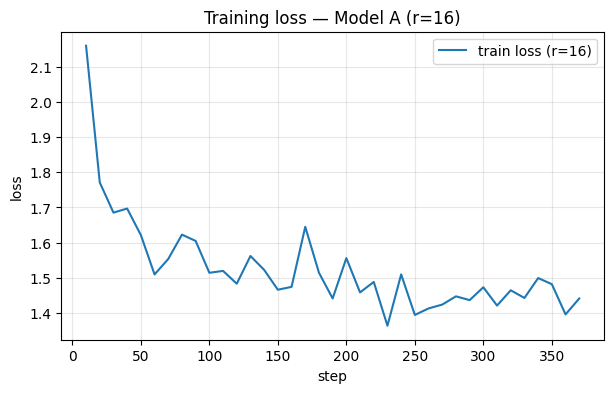

In [10]:
def loss_logs(trainer):
    h = trainer.state.log_history
    train = [(x["step"], x["loss"]) for x in h if "loss" in x]
    evals = [(x["epoch"], x["eval_loss"]) for x in h if "eval_loss" in x]
    return train, evals

train_a, eval_a = loss_logs(trainer_a)
print("Eval loss per epoch:", [(e, round(l, 4)) for e, l in eval_a])

plt.figure(figsize=(7, 4))
plt.plot(*zip(*train_a), label="train loss (r=16)")
plt.xlabel("step"); plt.ylabel("loss"); plt.title("Training loss — Model A (r=16)")
plt.legend(); plt.grid(alpha=.3); plt.show()

In [11]:
SAVE_A = "./lora_adapters/flan_t5_small_lora_r16"
model_a.save_pretrained(SAVE_A)
tokenizer.save_pretrained(SAVE_A)
print("Adapters saved to", SAVE_A)
print(os.listdir(SAVE_A))

Adapters saved to ./lora_adapters/flan_t5_small_lora_r16
['adapter_config.json', 'README.md', 'adapter_model.safetensors', 'tokenizer_config.json', 'tokenizer.json']


## Step 5 — Post-Fine-Tuning Inference (Model A)


In [12]:
reloaded_a = PeftModel.from_pretrained(
    AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME), SAVE_A).to(device)

finetuned_a_outputs = summarize(reloaded_a, sample_dialogues)

for i, (ref, base, ft) in enumerate(zip(sample_refs, baseline_outputs, finetuned_a_outputs)):
    print(f"===== Dialogue {i+1} =====")
    print("HUMAN SUMMARY      :", ref)
    print("FINE-TUNED (r=16)  :", ft, "\n")

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


===== Dialogue 1 =====
HUMAN SUMMARY      : Ms. Dawson helps #Person1# to write a memo to inform every employee that they have to change the communication method and should not use Instant Messaging anymore.
FINE-TUNED (r=16)  : #Person1# asks #Person2# to take a dictation for Ms. Dawson. #Person2# asks #Person1# to take a dictation for Ms. Dawson. 

===== Dialogue 2 =====
HUMAN SUMMARY      : #Person1# is about to make a prank. #Person2# thinks it's cruel at first but then joins.
FINE-TUNED (r=16)  : #Person1# tells #Person2# that #Person1#'s friends think it's cruel but #Person2# thinks it's cruel. 



## Step 6 — Output Comparison (Before vs After)

In [13]:
rouge = evaluate.load("rouge")

comparison = pd.DataFrame({
    "Human summary": sample_refs,
    "Before (baseline)": baseline_outputs,
    "After (LoRA r=16)": finetuned_a_outputs,
})
pd.set_option("display.max_colwidth", None)
display(comparison)

for label, preds in [("Baseline", baseline_outputs), ("LoRA r=16", finetuned_a_outputs)]:
    s = rouge.compute(predictions=preds, references=sample_refs)
    print(f"{label:10s} on the 2 samples -> ROUGE-1 {s['rouge1']:.3f} | ROUGE-L {s['rougeL']:.3f}")

,Human summary,Before (baseline),After (LoRA r=16)
0,Ms. Dawson helps #Person1# to write a memo to inform every employee that they have to change the communication method and should not use Instant Messaging anymore.,"Ms. Dawson, Attached is a draft memo to all employees.",#Person1# asks #Person2# to take a dictation for Ms. Dawson. #Person2# asks #Person1# to take a dictation for Ms. Dawson.
1,#Person1# is about to make a prank. #Person2# thinks it's cruel at first but then joins.,Talk to your friends.,#Person1# tells #Person2# that #Person1#'s friends think it's cruel but #Person2# thinks it's cruel.


Baseline   on the 2 samples -> ROUGE-1 0.183 | ROUGE-L 0.183
LoRA r=16  on the 2 samples -> ROUGE-1 0.334 | ROUGE-L 0.283


**What changed:**
- **Style:** the baseline produced short fragments copied from the dialogue ("Ms. Dawson, Attached is a draft memo to all employees.", "Talk to your friends."). After LoRA fine-tuning, the model writes DialogSum-style summaries in the third person, naming `#Person1#`/`#Person2#` and describing who did what. ROUGE-1 on the 2 samples rose from **0.183 to 0.334** (ROUGE-L 0.183 → 0.283).
- **Remaining weaknesses:** the fine-tuned model still misses the key point of dialogue 1 (the ban on Instant Messaging) and repeats itself. Dialogue 2 captures that #Person2# thinks the prank is cruel, but not that they then join in.
- This improvement came from training only **688,128 parameters (0.89%)** of the 77.6M-parameter model.

## Step 7 — Experiment: LoRA rank r = 4 vs r = 16


In [14]:
CONFIG_B = dict(name="lora_r4", r=4, alpha=8, dropout=0.05)
model_b = build_lora_model(CONFIG_B["r"], CONFIG_B["alpha"], CONFIG_B["dropout"])

print("LoRA config:", CONFIG_B)
total_b, trainable_b = count_params(model_b)

trainer_b, result_b = train_lora(model_b, CONFIG_B["name"])

SAVE_B = "./lora_adapters/flan_t5_small_lora_r4"
model_b.save_pretrained(SAVE_B)
print("Adapters saved to", SAVE_B)

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


LoRA config: {'name': 'lora_r4', 'r': 4, 'alpha': 8, 'dropout': 0.05}
Total parameters     : 77,133,184
Trainable parameters : 172,032
Trainable %          : 0.2230%


Epoch,Training Loss,Validation Loss
1,1.519375,1.347300
2,1.443288,1.323570
3,1.497399,1.324026



[lora_r4] Final training loss: 1.5827  | time: 143s
Adapters saved to ./lora_adapters/flan_t5_small_lora_r4


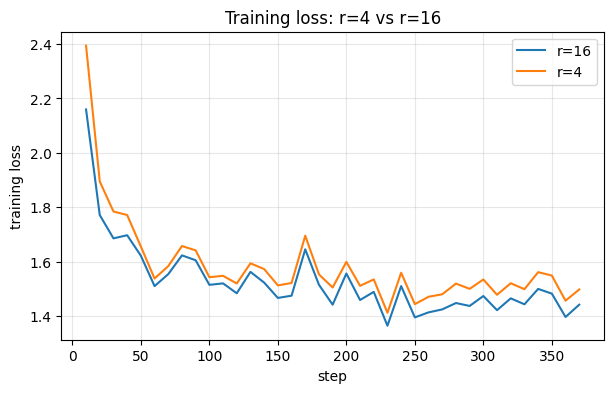

In [15]:
train_b, eval_b = loss_logs(trainer_b)

plt.figure(figsize=(7, 4))
plt.plot(*zip(*train_a), label="r=16")
plt.plot(*zip(*train_b), label="r=4")
plt.xlabel("step"); plt.ylabel("training loss"); plt.title("Training loss: r=4 vs r=16")
plt.legend(); plt.grid(alpha=.3); plt.show()

In [16]:
finetuned_b_outputs = summarize(model_b, sample_dialogues)

for i in range(2):
    print(f"===== Dialogue {i+1} =====")
    print("HUMAN     :", sample_refs[i])
    print("BASELINE  :", baseline_outputs[i])
    print("LoRA r=4  :", finetuned_b_outputs[i])
    print("LoRA r=16 :", finetuned_a_outputs[i], "\n")

===== Dialogue 1 =====
HUMAN     : Ms. Dawson helps #Person1# to write a memo to inform every employee that they have to change the communication method and should not use Instant Messaging anymore.
BASELINE  : Ms. Dawson, Attached is a draft memo to all employees.
LoRA r=4  : #Person1# asks #Person2# to take a dictation for Ms. Dawson. #Person2# asks #Person1# to take a dictation for Ms. Dawson.
LoRA r=16 : #Person1# asks #Person2# to take a dictation for Ms. Dawson. #Person2# asks #Person1# to take a dictation for Ms. Dawson. 

===== Dialogue 2 =====
HUMAN     : #Person1# is about to make a prank. #Person2# thinks it's cruel at first but then joins.
BASELINE  : Talk to your friends.
LoRA r=4  : #Person1# pulls on a strip and peels off the back. #Person2# thinks it's cruel.
LoRA r=16 : #Person1# tells #Person2# that #Person1#'s friends think it's cruel but #Person2# thinks it's cruel. 



In [17]:
# ROUGE on a larger held-out test subset for a fairer quality comparison
eval_set = dataset["test"].select(range(EVAL_SUBSET))
eval_dialogues, eval_refs = eval_set["dialogue"], eval_set["summary"]

def batch_summarize(model, dialogues, bs=16):
    preds = []
    for i in range(0, len(dialogues), bs):
        preds += summarize(model, dialogues[i:i + bs])
    return preds

results = {}
for label, m in [("Baseline (no LoRA)", base_model), ("LoRA r=4", model_b), ("LoRA r=16", model_a)]:
    preds = batch_summarize(m, eval_dialogues)
    results[label] = rouge.compute(predictions=preds, references=eval_refs)

summary_df = pd.DataFrame(results).T[["rouge1", "rouge2", "rougeL", "rougeLsum"]].round(4)
summary_df["trainable params"] = [0, trainable_b, trainable_a]
summary_df["final train loss"] = [np.nan, round(result_b.training_loss, 4), round(result_a.training_loss, 4)]
summary_df["final eval loss"]  = [np.nan, round(eval_b[-1][1], 4), round(eval_a[-1][1], 4)]
display(summary_df)
summary_df.to_csv("outputs/rank_experiment_results.csv")

,rouge1,rouge2,rougeL,rougeLsum,trainable params,final train loss,final eval loss
Baseline (no LoRA),0.1354,0.0429,0.1263,0.1265,0,NaN,NaN
LoRA r=4,0.3726,0.1200,0.3004,0.3002,172032,1.5827,1.3240
LoRA r=16,0.3575,0.1170,0.2886,0.2881,688128,1.5254,1.2943


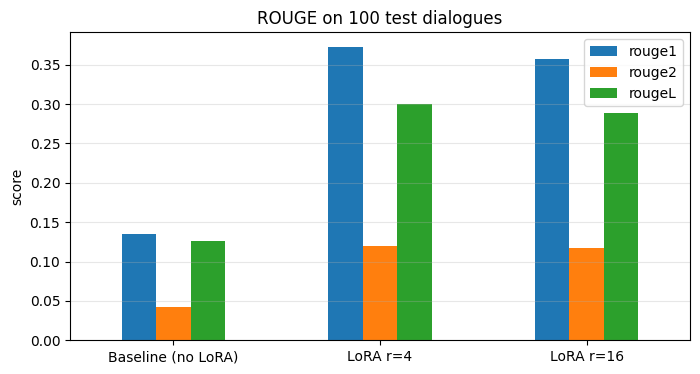

In [18]:
summary_df[["rouge1", "rouge2", "rougeL"]].plot(kind="bar", figsize=(8, 4), rot=0)
plt.title(f"ROUGE on {EVAL_SUBSET} test dialogues"); plt.ylabel("score"); plt.grid(axis="y", alpha=.3)
plt.show()

In [19]:
# "Final training loss" printed by trainer.train() is the AVERAGE over all steps.
# Show the loss at the end of epoch 3 alongside it for clarity.
for name, trainer, result in [("r=16", trainer_a, result_a), ("r=4", trainer_b, result_b)]:
    h = trainer.state.log_history
    last_train = [x["loss"] for x in h if "loss" in x][-1]
    last_eval  = [x["eval_loss"] for x in h if "eval_loss" in x][-1]
    print(f"LoRA {name:5s} | avg train loss (all steps): {result.training_loss:.4f} "
          f"| last logged train loss: {last_train:.4f} | final eval loss: {last_eval:.4f}")

LoRA r=16  | avg train loss (all steps): 1.5254 | last logged train loss: 1.4414 | final eval loss: 1.2943
LoRA r=4   | avg train loss (all steps): 1.5827 | last logged train loss: 1.4974 | final eval loss: 1.3240


### Findings: r = 4 vs r = 16

| Model | Trainable params | ROUGE-1 | ROUGE-2 | ROUGE-L | Final eval loss |
|---|---|---|---|---|---|
| Baseline | 0 | 0.1354 | 0.0429 | 0.1263 | — |
| LoRA r=4 | 172,032 (0.22%) | **0.3726** | **0.1200** | **0.3004** | 1.3240 |
| LoRA r=16 | 688,128 (0.89%) | 0.3575 | 0.1170 | 0.2886 | **1.2943** |

- **Both ranks far outperform the baseline**, with ROUGE-1 about 2.7× higher. Even a very small adapter is enough to teach the model the summary format.
- **r = 16 fits the data slightly better** (lower train and validation loss), but **r = 4 scored slightly higher on ROUGE**. The gap is about 1.5 ROUGE points on 100 test dialogues, which is small enough to be noise. Loss measures how well the model predicts the reference tokens, while ROUGE measures the summaries it actually generates, so the two don't always agree.
- On the 2 sample dialogues, both ranks gave the same summary for dialogue 1. For dialogue 2, r=4 was more coherent, while r=16 contradicted itself.
- **Conclusion:** with only 1,000 training examples and 3 epochs, raising the rank from 4 to 16 used 4× more trainable parameters without improving quality. **r = 4 is the more parameter-efficient choice.** Higher rank would likely only help with more data or a harder task.